# Steam game recommendations: implicit-feedback ALS against course methods

**Our outside-the-course method** is matrix factorisation for implicit feedback (Hu, Koren & Volinsky, 2008), fitted with alternating least squares (ALS). Every user and game gets a vector of hidden factors, and their dot product scores how likely the user is to play the game. Playtime is not treated as a rating but as *confidence*: a played game is a positive with confidence $c = 1 + \alpha \log(1 + \text{minutes})$, an unplayed game is a weak negative with confidence 1. ALS alternately solves for all user vectors with the game vectors fixed and the other way round; each half-step is a set of small least-squares problems, implemented from scratch in `recommender/als.py` (NumPy + Numba).

**Course methods** it is compared with: association rules from frequent itemsets (PCY for pairs, Apriori for triples; `recommender/itemsets.py`, `recommender/rules.py`), item-item similarity (cosine or Jaccard), and popularity. Clustering (spherical k-means with the Davies–Bouldin index) is used to describe the learned game vectors and to diversify the recommendation lists.

**Data:** the Australian Steam user inventories, reviews and game metadata from Julian McAuley's group at UCSD (https://cseweb.ucsd.edu/~jmcauley/datasets.html; Kang & McAuley, ICDM 2018; Wan & McAuley, RecSys 2018; Pathak, Gupta & McAuley, SIGIR 2017).

Outline:
1. Data: played games, one shared filter, train / validation / test split.
2. Tuning: every method is tuned on validation with the same rule.
3. Convergence of ALS.
4. Test results over five random splits, with bootstrap intervals.
5. Cross-check of our ALS against the `implicit` library.
6. What ALS learned: similar games, and clusters of game vectors compared with Steam tags.
7. Diversifying the lists by cluster.

**How to run.** From the repository root: `pip install -r requirements-recommender.txt`, then run all cells. The slow parts (tuning grids, test runs over five splits, convergence traces) are cached as CSV files in `results/`, so a re-run takes about 14 minutes; delete a file there to recompute that part (all of them: several hours on a 12-core laptop). The unit tests run with `pytest`.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

from recommender import als, baselines, clusters, data, diversify, evaluate, itemsets
from recommender import experiments as ex

FIGURES = Path(data.DATA_DIR).parent / "figures"
FIGURES.mkdir(exist_ok=True)
N_SEEDS = 5                    # random splits for the test results
CONVERGENCE_SEEDS = 3
CONVERGENCE_SWEEPS = 30
CLUSTER_KS = [10, 20, 40]      # numbers of clusters for diversification
CAPS = [1, 2, 3, 4, 5, 10]     # at most this many games per cluster in a top-10 list (10 = no cap)
CHECK_FACTORS = 128            # size of the cross-check against implicit (any size tests the code)
STABLE_ARI = 0.9               # clusters are described at the largest k this reproducible across seeds

## 1. Data

All methods share one data definition (`recommender/data.py`). The raw inventories repeat some users; duplicate (user, game) rows keep the largest playtime. A game counts for a user only if it was **played**: owned-but-unplayed games are left out, because bundles and giveaways make ownership weak evidence of taste, and every method is trained and scored on plays. Games need at least 50 players and users at least 5 played games; removing games can push users below 5 and the other way round, so the two filters repeat until both hold. Players are counted over all played games, including the ones hidden below for validation and testing, so a game can end up with fewer than 50 training players (the minimum is printed below).

In [2]:
raw = data.read_user_items()
user_items = data.deduplicate(raw)
print(f"{len(raw):,} raw user-game rows, {len(raw) - len(user_items):,} duplicates removed, "
      f"{(user_items['playtime'] > 0).sum():,} played")

inter = data.build_interactions(user_items)
n_users, n_games = inter.playtime.shape
display(inter.filter_log)
print(f"{n_users:,} users x {n_games:,} games: {inter.playtime.nnz / (n_users * n_games):.2%} of the matrix is played")

5,153,209 raw user-game rows, 59,127 duplicates removed, 3,246,352 played


,users,games,played pairs
step,,,
played entries,68403,10050,3246352
filter pass 1,59717,3720,3146315
filter pass 2,59716,3718,3146213
filter pass 3,59716,3718,3146213


59,716 users x 3,718 games: 1.42% of the matrix is played


For every user, 20% of their played games are hidden as the **test** set; of the rest, another 20% are hidden as the **validation** set used for all tuning. The filter runs before the split, so it defines the population we evaluate: active users and games with at least 50 players. Recommending niche games is therefore not measured.

In [3]:
train_full, test = data.split_per_user(inter.playtime, test_frac=0.2, seed=0)
train, valid = data.split_per_user(train_full, test_frac=0.2, seed=1)
print(f"train {train.nnz:,}  validation {valid.nnz:,}  test {test.nnz:,} played pairs")

players = data.players_per_game(train)
print("training players per game: min {}, quartiles {}".format(players.min(), np.percentile(players, [25, 50, 75])))

train 2,013,843  validation 503,425  test 628,945 played pairs
training players per game: min 20, quartiles [ 58.   128.5  397.75]


## 2. Tuning every method with the same rule

Each method gets a grid of settings, scored on the validation games by NDCG@10. The same rule picks the setting for every method:

- **One-standard-error rule:** take the simplest setting whose NDCG is within one standard error (over users) of the best. "Simpler" is fixed in advance: pairs-only rules before rules with triples and higher supports before lower ones; fewer neighbours for item-kNN; fewer factors and then larger λ for ALS.
- **Two ALS variants**, with and without idf weighting, are each chosen this way. The same rule then picks the headline ALS model: idf weighting is the extra step, so it is used only if its NDCG is more than one standard error above the unweighted model's. (In our first test run the headline was simply the variant with the higher validation NDCG; we changed it to this rule afterwards so that every choice follows the same rule.)
- **Edge check:** the best value of every ordered setting should lie inside the range tried, so that more tuning would be unlikely to change the comparison. Allowed edges are natural bounds (pairs only; one or all neighbours) and the stated compute cap of 512 factors. For ALS, a best λ or α at the edge makes the grid grow one step further out until it is inside (see below).

A well-tuned simple baseline is the real test for a learned model (Ferrari Dacrema et al., 2019), so the baselines get wide grids. They are the textbook forms from the course (no shrinkage or other refinements), so a more elaborate kNN could narrow the gap.

### Association rules (frequent itemsets)

Rules come from the frequent itemsets of the training baskets: pairs with support ≥ `pair_support` (PCY), and optionally triples with support ≥ `triple_support` (Apriori), which add rules with two-game premises {a, b} → c. A user's score for a game is the strongest rule into it (`max`) or the sum of all of them (`sum`). Supports are counts of users in the tuning split.

In [4]:
triple_cache = {}  # triples depend only on their support, so mine each support once
rules_grid = ex.run_grid("tune_rules", ex.rule_configs(), lambda c: ex.score(
    ex.rules_scorer(train, c["pair_support"], c["triple_support"], c["aggregate"], triple_cache), train, valid))
rules_grid["uses triples"] = rules_grid["triple_support"] > 0
rule_simplicity = [("uses triples", True), ("pair_support", False), ("triple_support", False)]

rules_pairs, _ = ex.one_se_choice(rules_grid[~rules_grid["uses triples"]], rule_simplicity)
rules_triples, _ = ex.one_se_choice(rules_grid[rules_grid["uses triples"]], rule_simplicity)
rules_choice, rules_best = ex.one_se_choice(rules_grid, rule_simplicity)

display(rules_grid.sort_values("ndcg@10", ascending=False).head(8).round(4))
display(ex.edge_check(rules_grid, rules_best, ["pair_support", "triple_support", "aggregate"],
                      ["pair_support", "triple_support"], {"triple_support": [0]}))
print(f"chosen pairs-only {rules_pairs['ndcg@10']:.4f}, chosen with triples {rules_triples['ndcg@10']:.4f} "
      f"(SE {rules_pairs['ndcg_se']:.4f})")

,pair_support,triple_support,aggregate,precision@10,recall@10,ndcg@10,ndcg_se,coverage,uses triples
8,60,0,max,0.1382,0.2371,0.2399,0.0009,0.1022,False
16,120,0,max,0.1378,0.2367,0.2395,0.0009,0.0689,False
12,60,150,max,0.1393,0.2395,0.2394,0.0009,0.0858,True
4,30,150,max,0.1394,0.2397,0.2394,0.0009,0.1240,True
14,60,300,max,0.1383,0.2378,0.2387,0.0009,0.0871,True
20,120,150,max,0.1384,0.2387,0.2385,0.0009,0.0600,True
0,30,0,max,0.1374,0.2362,0.2385,0.0009,0.1503,False
6,30,300,max,0.1382,0.2378,0.2383,0.0009,0.1315,True


,setting,best,tried,at edge,allowed edge
0,pair_support,60,"[30, 60, 120, 250]",False,False
1,triple_support,0,"[0, 60, 150, 300]",True,True


chosen pairs-only 0.2395, chosen with triples 0.2385 (SE 0.0009)


### Item-item similarity (item-kNN)

A user's score for a game is the summed similarity between it and the games they played, keeping each game's `k` most similar games. Similarity is cosine or Jaccard (the similar-items measure from the course) of the two games' player sets; `k` = number of games means all neighbours.

In [5]:
knn_grid = ex.run_grid("tune_knn", ex.knn_configs(n_games), lambda c: ex.score(
    ex.knn_scorer(train, c["measure"], c["k"]), train, valid))
knn_choice, knn_best = ex.one_se_choice(knn_grid, [("k", True)])

display(knn_grid.sort_values("ndcg@10", ascending=False).head(8).round(4))
display(ex.edge_check(knn_grid, knn_best, ["measure", "k"], ["k"], {"k": [1, n_games]}))

,measure,k,precision@10,recall@10,ndcg@10,ndcg_se,coverage
16,cosine,5,0.1359,0.2379,0.2295,0.0009,0.5551
15,cosine,2,0.1316,0.2287,0.2279,0.0009,0.6307
19,jaccard,5,0.1330,0.2292,0.2211,0.0009,0.5382
18,jaccard,2,0.1276,0.2194,0.2200,0.0009,0.6450
0,cosine,10,0.1298,0.2282,0.2194,0.0009,0.3195
6,cosine,3718,0.1231,0.2179,0.2173,0.0009,0.2039
5,cosine,500,0.1227,0.2170,0.2166,0.0009,0.1982
4,cosine,200,0.1215,0.2143,0.2145,0.0009,0.1942


,setting,best,tried,at edge,allowed edge
0,k,5,"[1, 2, 5, 10, 20, 50, 100, 200, 500, 3718]",False,False


### ALS

Four stages, because a full grid over four settings is too slow:
1. Factors {64, 128, 256} × λ from 30 to 3000 (α = 3, no weighting), plus λ ∈ {1, 10} at 128 factors to show what happens without strong regularisation.
2. 512 factors (the compute cap) at the λ values around the best 256-factor λ.
3. α ∈ {1, 3, 10} with and without **idf weighting** around the best (factors, λ). idf weighting multiplies each game's playtime term by log(users / players), scaled to mean 1, so plays of niche games count for more than plays of games everyone has.
4. Edge extensions, repeated until nothing is added: for every (weighting, α) whose best λ is the smallest or largest tried, the next λ further out (`ex.reg_extensions`); for every weighting whose best α (each α at its own best λ) is the smallest or largest tried, the next α in {0.3, 1, 3, 10, 30, 100} at the λ values around the best (`ex.alpha_extensions`), after which its λ is tuned the same way.

Every fit runs 15 sweeps; the last column is the relative change of the loss in the last sweep, so convergence can be checked for every setting, not only the one traced in Section 3.

In [6]:
def als_eval(cfg):
    model, change = ex.als_with_convergence(train, cfg)
    return {**ex.score(evaluate.als_scorer(model), train, valid), "last_sweep_loss_change": change}

als_keys = ex.ALS_KEYS
stage1 = ex.run_grid("tune_als", ex.als_stage1_configs(), als_eval)
cap = ex.run_grid("tune_als", ex.als_cap_configs(stage1), als_eval)
stage2 = ex.run_grid("tune_als", ex.als_stage2_configs(pd.concat([stage1, cap])), als_eval)
als_grid = pd.concat([stage1, cap, stage2]).drop_duplicates(als_keys, ignore_index=True)
before_extensions = len(als_grid)
while extension := ex.reg_extensions(als_grid) + ex.alpha_extensions(als_grid):
    als_grid = pd.concat([als_grid, ex.run_grid("tune_als", extension, als_eval)]).drop_duplicates(
        als_keys, ignore_index=True)
print(f"edge extensions added {len(als_grid) - before_extensions} settings")

als_simplicity = [("factors", True), ("reg", False)]
als_choice, als_best = ex.one_se_choice(als_grid[als_grid["weighting"] == "none"], als_simplicity)
idf_choice, idf_best = ex.one_se_choice(als_grid[als_grid["weighting"] == "idf"], als_simplicity)
variants = pd.DataFrame([als_choice, idf_choice]).assign(method=["ALS", "ALS + idf"], uses_idf=[False, True])
best_als = ex.one_se_choice(variants, [("uses_idf", True)])[0]["method"]  # idf only if > 1 SE better
chosen_als = {k: (als_choice if best_als == "ALS" else idf_choice)[k] for k in als_keys}

display(als_grid.sort_values("ndcg@10", ascending=False).head(10).round(4))
display(pd.concat([
    ex.edge_check(als_grid, best, als_keys, ["factors", "alpha", "reg"], {"factors": [ex.ALS_MAX_FACTORS]},
                  free={"alpha": ["reg"]})
      .assign(variant=name) for name, best in [("ALS", als_best), ("ALS + idf", idf_best)]
], ignore_index=True))
print("validation NDCG at 512 factors, per (weighting, α) and λ:")
display(als_grid[als_grid["factors"] == ex.ALS_MAX_FACTORS].pivot_table(
    index=["weighting", "alpha"], columns="reg", values="ndcg@10").round(4))
print(f"chosen NDCG: ALS {als_choice['ndcg@10']:.4f}, ALS + idf {idf_choice['ndcg@10']:.4f} "
      f"(SE {idf_choice['ndcg_se']:.4f}); headline ALS variant: {best_als}")
print(f"{len(als_grid)} settings; largest last-sweep loss change {als_grid['last_sweep_loss_change'].max():.2e}")

edge extensions added 16 settings


,weighting,alpha,factors,reg,precision@10,recall@10,ndcg@10,ndcg_se,coverage,last_sweep_loss_change
59,idf,10.0,512,375.0,0.1533,0.2628,0.2576,0.0009,0.4067,0.0001
49,idf,3.0,512,200.0,0.1542,0.2604,0.2569,0.0009,0.3332,0.0000
57,none,10.0,512,375.0,0.1522,0.2627,0.2564,0.0009,0.3895,0.0004
50,idf,3.0,512,250.0,0.1529,0.2590,0.2563,0.0009,0.2405,0.0000
35,none,3.0,512,250.0,0.1533,0.2604,0.2561,0.0009,0.2630,0.0000
54,idf,10.0,512,300.0,0.1525,0.2617,0.2560,0.0009,0.4701,0.0002
36,none,3.0,512,300.0,0.1523,0.2589,0.2555,0.0009,0.2095,0.0000
60,none,10.0,512,450.0,0.1517,0.2623,0.2555,0.0009,0.3453,0.0002
21,none,3.0,256,300.0,0.1516,0.2581,0.2543,0.0009,0.2071,0.0000
62,idf,10.0,512,450.0,0.1513,0.2595,0.2537,0.0009,0.3564,0.0001


,setting,best,tried,at edge,allowed edge,variant
0,factors,512.0,[512],False,True,ALS
1,alpha,10.0,"[1.0, 3.0, 10.0, 30.0]",False,False,ALS
2,reg,375.0,"[200.0, 250.0, 300.0, 375.0, 450.0]",False,False,ALS
3,factors,512.0,[512],False,True,ALS + idf
4,alpha,10.0,"[1.0, 3.0, 10.0, 30.0]",False,False,ALS + idf
5,reg,375.0,"[200.0, 250.0, 300.0, 375.0, 450.0]",False,False,ALS + idf


validation NDCG at 512 factors, per (weighting, α) and λ:


reg               30.0    100.0   200.0   250.0   300.0   375.0   450.0  \
weighting alpha                                                           
idf       1.0    0.1225  0.2450  0.2364  0.2239  0.2127     NaN     NaN   
          3.0       NaN  0.2052  0.2569  0.2563  0.2476     NaN     NaN   
          10.0      NaN     NaN  0.2345  0.2488  0.2560  0.2576  0.2537   
          30.0      NaN     NaN     NaN     NaN  0.2403  0.2483  0.2513   
none      1.0       NaN  0.2360  0.2492  0.2417  0.2330     NaN     NaN   
          3.0       NaN     NaN  0.2522  0.2561  0.2555  0.2502  0.2422   
          10.0      NaN     NaN  0.2278  0.2443  0.2525  0.2564  0.2555   
          30.0      NaN     NaN     NaN     NaN  0.2109  0.2350  0.2454   

reg               700.0  
weighting alpha          
idf       1.0       NaN  
          3.0       NaN  
          10.0      NaN  
          30.0   0.2452  
none      1.0       NaN  
          3.0       NaN  
          10.0      NaN  
          30.0   0.2448

chosen NDCG: ALS 0.2555, ALS + idf 0.2576 (SE 0.0009); headline ALS variant: ALS + idf
71 settings; largest last-sweep loss change 6.20e-03


Validation NDCG against λ for each number of factors (α = 3, no weighting). Too little regularisation lets the larger models overfit; the drop on the small-λ side is much steeper than on the large-λ side.

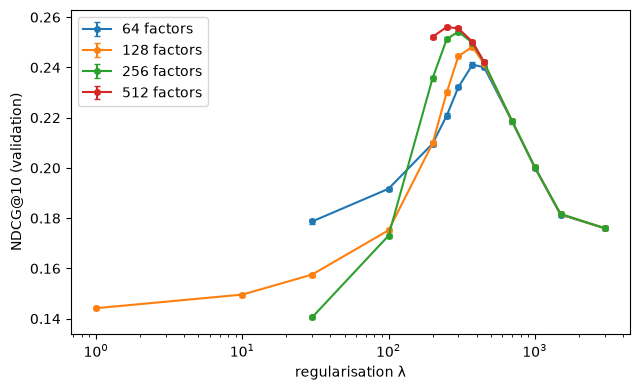

reg,1.0,10.0,30.0,100.0,200.0,250.0,300.0,375.0,450.0,700.0,1000.0,1500.0,3000.0
factors,,,,,,,,,,,,,
64,NaN,NaN,0.1787,0.1917,0.2097,0.2208,0.2321,0.2411,0.2401,0.2185,0.2001,0.1814,0.176
128,0.1442,0.1496,0.1575,0.1752,0.2097,0.2300,0.2445,0.2482,0.2414,0.2186,0.2002,0.1815,0.176
256,NaN,NaN,0.1405,0.1730,0.2357,0.2512,0.2543,0.2498,0.2420,0.2186,0.2003,0.1817,0.176
512,NaN,NaN,NaN,NaN,0.2522,0.2561,0.2555,0.2502,0.2422,NaN,NaN,NaN,NaN


In [7]:
curve = als_grid[(als_grid["weighting"] == "none") & (als_grid["alpha"] == ex.ALS_ALPHA)]
fig, ax = plt.subplots(figsize=(6.5, 4))
for factors, part in curve.groupby("factors"):
    part = part.sort_values("reg")
    ax.errorbar(part["reg"], part["ndcg@10"], yerr=part["ndcg_se"], marker="o", ms=4, capsize=2, label=f"{factors} factors")
ax.set_xscale("log")
ax.set_xlabel("regularisation λ")
ax.set_ylabel("NDCG@10 (validation)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "als_lambda.pdf")
plt.show()
display(curve.pivot_table(index="factors", columns="reg", values="ndcg@10").round(4))

### Chosen settings

The table lists, per method, how many settings were tried, the setting the one-SE rule picked, and its validation NDCG next to the best one.

In [8]:
def describe(row, keys):
    return ", ".join(f"{k}={row[k]:g}" if isinstance(row[k], (int, float, np.integer, np.floating)) else f"{k}={row[k]}" for k in keys)

rule_keys = ["pair_support", "triple_support", "aggregate"]
summary = pd.DataFrame([
    ("Association rules (pairs)", (~rules_grid["uses triples"]).sum(), describe(rules_pairs, rule_keys), rules_pairs["ndcg@10"], rules_grid.loc[~rules_grid["uses triples"], "ndcg@10"].max()),
    ("Association rules (pairs + triples)", rules_grid["uses triples"].sum(), describe(rules_triples, rule_keys), rules_triples["ndcg@10"], rules_grid.loc[rules_grid["uses triples"], "ndcg@10"].max()),
    ("Item-kNN", len(knn_grid), describe(knn_choice, ["measure", "k"]), knn_choice["ndcg@10"], knn_grid["ndcg@10"].max()),
    ("ALS", (als_grid["weighting"] == "none").sum(), describe(als_choice, als_keys), als_choice["ndcg@10"], als_grid.loc[als_grid["weighting"] == "none", "ndcg@10"].max()),
    ("ALS + idf", (als_grid["weighting"] == "idf").sum(), describe(idf_choice, als_keys), idf_choice["ndcg@10"], als_grid.loc[als_grid["weighting"] == "idf", "ndcg@10"].max()),
], columns=["method", "settings tried", "chosen setting", "chosen NDCG@10", "best NDCG@10"])
display(summary.round(4))

,method,settings tried,chosen setting,chosen NDCG@10,best NDCG@10
0,Association rules (pairs),8,"pair_support=120, triple_support=0, aggregate=max",0.2395,0.2399
1,Association rules (pairs + triples),24,"pair_support=120, triple_support=150, aggregat...",0.2385,0.2394
2,Item-kNN,20,"measure=cosine, k=5",0.2295,0.2295
3,ALS,53,"weighting=none, alpha=10, factors=512, reg=450",0.2555,0.2564
4,ALS + idf,18,"weighting=idf, alpha=10, factors=512, reg=375",0.2576,0.2576


## 3. Convergence of ALS

Training loss and validation NDCG after every sweep for the chosen setting of the headline ALS variant, from three random starting points, run to 30 sweeps. The loss is computed sparsely (`als.loss`), without forming the full users × games matrix.

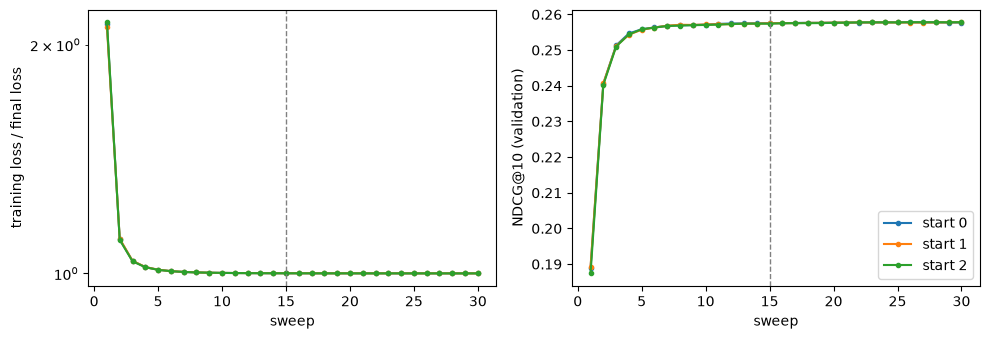

NDCG at sweep 15: [0.2576, 0.2575, 0.2574]; at sweep 30: [0.2577, 0.2578, 0.2578]
loss within 1% of its final value from sweep 6; mean NDCG peaks at sweep 30 (0.2578)


In [9]:
slug = "_".join(f"{k}{chosen_als[k]:g}" if k != "weighting" else chosen_als[k] for k in als_keys)
trace = ex.cached_table(f"convergence_{slug}_sweeps{CONVERGENCE_SWEEPS}_starts{CONVERGENCE_SEEDS}", lambda: pd.concat(
    [ex.convergence_trace(train, valid, chosen_als, seed, CONVERGENCE_SWEEPS) for seed in range(CONVERGENCE_SEEDS)]))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for seed, part in trace.groupby("seed"):
    axes[0].plot(part["sweep"], part["loss"] / part["loss"].iloc[-1], marker=".", label=f"start {seed}")
    axes[1].plot(part["sweep"], part["ndcg@10"], marker=".", label=f"start {seed}")
axes[0].set_ylabel("training loss / final loss")
axes[0].set_yscale("log")
axes[1].set_ylabel("NDCG@10 (validation)")
for ax in axes:
    ax.axvline(ex.ITERATIONS, color="grey", ls="--", lw=1)
    ax.set_xlabel("sweep")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIGURES / "als_convergence.pdf")
plt.show()

at = trace.pivot(index="sweep", columns="seed", values="ndcg@10")
print(f"NDCG at sweep {ex.ITERATIONS}: {at.loc[ex.ITERATIONS].round(4).tolist()}; at sweep {CONVERGENCE_SWEEPS}: {at.loc[CONVERGENCE_SWEEPS].round(4).tolist()}")
loss_ratio = trace.groupby("seed")["loss"].transform(lambda s: s / s.iloc[-1])
peak = at.mean(axis=1)
print(f"loss within 1% of its final value from sweep {trace.loc[loss_ratio < 1.01, 'sweep'].min()}; "
      f"mean NDCG peaks at sweep {peak.idxmax()} ({peak.max():.4f})")

## 4. Test results

Each method is refitted on training + validation games with its chosen setting and scored once on the test games. Refitting brings back the validation games, so each basket holds about 1.25× as many games; a support threshold for k-item sets is scaled by that factor to the power k so it keeps its meaning (`itemsets.scale_support`).

The whole comparison is repeated on five random splits (seed 0 is the split used for tuning; the settings stay fixed). The other four splits hide different games, so some of their test games were training or validation games during tuning: they show how much the result moves with the split, but they are not fresh held-out data. Besides accuracy we report:
- **coverage**: share of all games recommended to at least one user;
- **long-tail share**: share of recommended slots filled with games outside the 20% most-played;
- **intra-list similarity**: mean cosine similarity (of the games' player sets) between the games in a list; lower means more varied lists.

In [10]:
def scaled(cfg):
    return {
        "pair_support": itemsets.scale_support(int(cfg["pair_support"]), train, train_full, 2),
        "triple_support": itemsets.scale_support(int(cfg["triple_support"]), train, train_full, 3),
        "aggregate": str(cfg["aggregate"]),
    }

as_als = lambda row: {"weighting": str(row["weighting"]), "alpha": float(row["alpha"]),
                      "factors": int(row["factors"]), "reg": float(row["reg"])}
settings = {
    "rules_pairs": scaled(rules_pairs),
    "rules_triples": scaled(rules_triples),
    "knn": {"measure": str(knn_choice["measure"]), "k": int(knn_choice["k"])},
    "als": as_als(als_choice),
    "als_idf": as_als(idf_choice),
    "headline": best_als,
}
print(f"games per basket grow {train_full.nnz / train.nnz:.3f}x on refit; settings: {settings}")

test_scores, diversity, per_user = ex.test_runs(inter.playtime, list(range(N_SEEDS)), settings, CLUSTER_KS, CAPS)

games per basket grow 1.250x on refit; settings: {'rules_pairs': {'pair_support': 187, 'triple_support': 0, 'aggregate': 'max'}, 'rules_triples': {'pair_support': 187, 'triple_support': 293, 'aggregate': 'max'}, 'knn': {'measure': 'cosine', 'k': 5}, 'als': {'weighting': 'none', 'alpha': 10.0, 'factors': 512, 'reg': 450.0}, 'als_idf': {'weighting': 'idf', 'alpha': 10.0, 'factors': 512, 'reg': 375.0}, 'headline': 'ALS + idf'}


**Split 0** with 95% bootstrap intervals for NDCG (users resampled 10,000 times). Coverage is not bootstrapped: it counts distinct games over all users, and a resample holds only about 1 − 1/e ≈ 63% distinct users (Efron & Tibshirani, 1993), which would bias it downwards; its spread over the five splits is shown further down.

In [11]:
metric_cols = ["precision@10", "recall@10", "ndcg@10", "coverage", "long tail share", "intra-list similarity"]
split0 = test_scores[test_scores["seed"] == 0].set_index("method")[metric_cols]
split0.insert(3, "NDCG 95% interval", [
    "[{:.3f}, {:.3f}]".format(*evaluate.bootstrap_interval(per_user[m])) for m in split0.index])
display(split0.round(3))
split0.round(4).to_csv(FIGURES / "test_results.csv")
print(f"for comparison, share of the test games themselves in the long tail: "
      f"{evaluate.long_tail_share(test.indices, evaluate.popularity_counts(train_full)):.3f}")

,precision@10,recall@10,ndcg@10,NDCG 95% interval,coverage,long tail share,intra-list similarity
method,,,,,,,
Popularity,0.136,0.182,0.223,"[0.221, 0.224]",0.012,0.000,0.376
Rules (pairs),0.197,0.258,0.321,"[0.319, 0.323]",0.071,0.002,0.337
Rules (pairs + triples),0.199,0.261,0.322,"[0.320, 0.324]",0.061,0.000,0.342
Item-kNN,0.195,0.260,0.302,"[0.300, 0.304]",0.509,0.037,0.282
ALS,0.225,0.296,0.350,"[0.348, 0.352]",0.384,0.012,0.258
ALS + idf,0.229,0.298,0.356,"[0.354, 0.358]",0.448,0.019,0.254


for comparison, share of the test games themselves in the long tail: 0.207


**Paired differences** on split 0: both methods are scored on the same users, so the bootstrap resamples the per-user differences. "Best course method" is the course method with the highest validation NDCG (chosen before looking at the test set). We make four comparisons, so each interval uses the Bonferroni correction (level 1 − 0.05/4), in the spirit of the Bonferroni principle from the course: the more comparisons, the more likely one of them looks real by chance.

In [12]:
course_methods = {"Rules (pairs)": rules_pairs["ndcg@10"], "Rules (pairs + triples)": rules_triples["ndcg@10"],
                  "Item-kNN": knn_choice["ndcg@10"]}
best_course = max(course_methods, key=course_methods.get)  # chosen on validation, not test
print(f"best course method on validation: {best_course}")
comparisons = [(best_als, best_course), ("ALS", "ALS + idf"),
               ("Rules (pairs + triples)", "Rules (pairs)"), (best_course, "Popularity")]
level = 1 - 0.05 / len(comparisons)
display(pd.DataFrame([
    {"comparison": f"{a} − {b}", **evaluate.paired_difference(per_user[a], per_user[b], level=level)}
    for a, b in comparisons
]).round(4))

best course method on validation: Rules (pairs)


,comparison,difference,low,high,se
0,ALS + idf − Rules (pairs),0.0348,0.0329,0.0368,0.0008
1,ALS − ALS + idf,-0.0059,-0.0067,-0.0052,0.0003
2,Rules (pairs + triples) − Rules (pairs),0.0007,-0.0000,0.0014,0.0003
3,Rules (pairs) − Popularity,0.0986,0.0969,0.1004,0.0007


**All five splits**: mean ± standard deviation over splits, and whether the order of the methods by NDCG ever changes.

In [13]:
over_splits = test_scores.groupby("method")[["ndcg@10", "coverage", "long tail share", "intra-list similarity"]].agg(["mean", "std"])
display(over_splits.sort_values(("ndcg@10", "mean"), ascending=False).round(4))

orders = test_scores.sort_values(["seed", "ndcg@10"], ascending=[True, False]).groupby("seed")["method"].apply(tuple)
print("same NDCG order on every split:", orders.nunique() == 1)
print(orders.iloc[0])

ndcg@10         coverage         long tail share  \
                           mean     std     mean     std            mean   
method                                                                     
ALS + idf                0.3547  0.0013   0.4518  0.0031          0.0189   
ALS                      0.3487  0.0013   0.3834  0.0026          0.0122   
Rules (pairs + triples)  0.3218  0.0009   0.0606  0.0005          0.0005   
Rules (pairs)            0.3213  0.0006   0.0699  0.0008          0.0013   
Item-kNN                 0.3018  0.0008   0.5087  0.0035          0.0376   
Popularity               0.2219  0.0008   0.0128  0.0006          0.0000   

                                intra-list similarity          
                            std                  mean     std  
method                                                         
ALS + idf                0.0001                0.2542  0.0002  
ALS                      0.0001                0.2585  0.0001  
Rules (pairs + triples)  0.0001                0.3431  0.0004  
Rules (pairs)            0.0003                0.3374  0.0004  
Item-kNN                 0.0004                0.2825  0.0006  
Popularity               0.0000                0.3761  0.0003

same NDCG order on every split: True
('ALS + idf', 'ALS', 'Rules (pairs + triples)', 'Rules (pairs)', 'Item-kNN', 'Popularity')


## 5. Cross-check against the `implicit` library

`implicit` implements the same paper. It reads every stored value as the confidence itself (c = α · value), so we give it our confidence matrix with α = 1, start it from our exact initial vectors, and use its exact (Cholesky) solver. If both implementations are right, the two models must give the same scores. (The unit test `tests/test_als.py` checks a single least-squares solve against `implicit` to 1e-12; here we check whole fits, at `CHECK_FACTORS` = 128 factors to keep `implicit`'s run short.)

In [14]:
from implicit.cpu.als import AlternatingLeastSquares

check = {**chosen_als, "weighting": "none", "factors": CHECK_FACTORS}
conf = als.confidence(train_full, check["alpha"])
ours = als.fit(conf, check["factors"], check["reg"], ex.ITERATIONS, seed=0)

lib = AlternatingLeastSquares(factors=check["factors"], regularization=check["reg"], alpha=1.0,
                              iterations=ex.ITERATIONS, use_cg=False, dtype=np.float64, random_state=0)
lib.user_factors, lib.item_factors = (v.copy() for v in als.initial_factors(conf.shape, check["factors"], seed=0))
lib.fit(conf, show_progress=False)
theirs = als.ALSModel(np.asarray(lib.user_factors), np.asarray(lib.item_factors))

sample = np.arange(5000)
gap = np.abs(ours.user_factors[sample] @ ours.item_factors.T - theirs.user_factors[sample] @ theirs.item_factors.T).max()
differing = (evaluate.top_k(evaluate.als_scorer(ours), train_full) !=
             evaluate.top_k(evaluate.als_scorer(theirs), train_full)).any(axis=1).sum()
print(f"largest score difference (first 5,000 users): {gap:.1e}; "
      f"users whose top-10 lists differ: {differing} of {n_users:,}")

largest score difference (first 5,000 users): 2.0e-08; users whose top-10 lists differ: 0 of 59,716


## 6. What ALS learned

The headline ALS model, refitted on split 0's training + validation games.

In [15]:
final = ex.fit_als(train_full, **settings["als" if best_als == "ALS" else "als_idf"], seed=0)  # headline variant
name_to_index = {inter.item_names[g]: i for i, g in enumerate(inter.item_ids)}
title = lambda i: inter.item_names[inter.item_ids[i]]

similar = {}
for game in ["Counter-Strike: Global Offensive", "Euro Truck Simulator 2", "Dark Souls: Prepare to Die Edition"]:
    top, _ = als.similar_items(final, name_to_index[game], 6)
    similar[game] = [title(i) for i in top]
display(pd.DataFrame(similar))

,Counter-Strike: Global Offensive,Euro Truck Simulator 2,Dark Souls: Prepare to Die Edition
0,Garry's Mod,American Truck Simulator,DARK SOULS™ II
1,Left 4 Dead 2,Spintires,DARK SOULS™ II: Scholar of the First Sin
2,Unturned,Bus Driver,DARK SOULS III
3,PAYDAY 2,Train Simulator,The Witcher 2: Assassins of Kings Enhanced Edi...
4,Counter-Strike: Source,Trucks & Trailers,Skyrim Script Extender (SKSE)
5,Terraria,Microsoft Flight Simulator X: Steam Edition,The Witcher: Enhanced Edition


### Clusters of game vectors

ALS scores a user–game pair by a dot product, so a game's taste profile is the **direction** of its vector; the length mostly reflects how much data the game has (the correlation below). We therefore cluster directions with **spherical k-means** (Dhillon & Modha, 2001; `clusters.spherical_kmeans`, seeded with k-means++): every vector is scaled to length 1, games are assigned to the centroid with the highest cosine similarity, and centroids are scaled back to length 1 after each update. Plain k-means on unit vectors only approximates this, because its centroids are shorter than 1. DBSCAN is not used because it leaves noise points without a cluster, and the diversification below needs every game to have one.

For each k: Davies–Bouldin index (lower is better), adjusted mutual information (AMI) between clusters and each game's most-voted *content* tag (meta tags such as Indie or Early Access skipped; AMI is adjusted so that random labels score 0 at any k; Vinh, Epps & Bailey, 2010), the AMI of shuffled clusters, the agreement between runs from different random starts (adjusted Rand index, 1 = identical), and the share of all ALS top-10 slots that fall in the single most-recommended cluster.

In [16]:
players_full = data.players_per_game(train_full)
lengths = np.linalg.norm(final.item_factors, axis=1)
print(f"Spearman correlation between vector length and number of players: {spearmanr(lengths, players_full).statistic:.2f}")

game_tags = clusters.load_game_tags()
tagged = np.array([g in game_tags for g in inter.item_ids])
tag_lists = [game_tags[g] for g in inter.item_ids[tagged]]
print(f"{tagged.sum():,} of {n_games:,} games have a record with tags in steam_games.json.gz")

final_recs = evaluate.top_k(evaluate.als_scorer(final), train_full)
sweep, labels_by_k = clusters.kmeans_sweep(final.item_factors, [5, 10, 20, 40, 80])
extra = []
for k in sweep["k"]:
    ami, shuffled = clusters.ami_with_top_tag(labels_by_k[k][tagged], tag_lists)
    extra.append({
        "AMI": ami, "AMI shuffled": shuffled,
        "seed agreement (ARI)": clusters.seed_agreement(final.item_factors, k, [0, 1, 2]),
        "largest cluster share of top-10": clusters.largest_cluster_share(final_recs, labels_by_k[k]),
    })
sweep = pd.concat([sweep, pd.DataFrame(extra)], axis=1)
display(sweep.round(3))

Spearman correlation between vector length and number of players: 0.93


3,206 of 3,718 games have a record with tags in steam_games.json.gz


,k,davies_bouldin,AMI,AMI shuffled,seed agreement (ARI),largest cluster share of top-10
0,5,4.058,0.155,0.001,0.964,0.682
1,10,3.653,0.197,0.000,0.855,0.836
2,20,3.524,0.213,-0.000,0.579,0.831
3,40,3.350,0.243,-0.001,0.483,0.524
4,80,3.119,0.253,-0.001,0.498,0.444


The Davies–Bouldin index falls steadily as k grows, so it has no minimum inside the range and does not choose k. Its values are well above 1: for a typical cluster, its spread plus that of its closest neighbour exceeds the distance between their centres, so the game vectors do not split into well-separated groups, and the clusters are best read as regions of taste rather than distinct types. We describe the clusters at the largest k whose clustering comes out (almost) the same from different random starts (seed agreement ≥ 0.9), because a description of clusters that change with the seed would not mean much. Each cluster is described by tags that are both common in it (on at least 20% of its games) and over-represented compared with all games (lift above 1).

In [17]:
describe_k = int(sweep.loc[sweep["seed agreement (ARI)"] >= STABLE_ARI, "k"].max())
print(f"described at k = {describe_k}")
labels = labels_by_k[describe_k]
profile = clusters.tag_profile(labels[tagged], tag_lists)
# Median training players per cluster (all games, tagged or not), to see whether a cluster is a
# taste group or mostly a popularity band, and each cluster's share of all ALS top-10 slots.
profile.insert(2, "median players", [int(np.median(players_full[labels == c])) for c in profile["cluster"]])
profile.insert(3, "share of top-10 slots", [round(float((labels[final_recs] == c).mean()), 3) for c in profile["cluster"]])
with pd.option_context("display.max_colwidth", None):
    display(profile)

described at k = 5


,cluster,games,median players,share of top-10 slots,tags (share in cluster vs overall)
0,0,856,118,0.011,"Puzzle (33% vs 17%), Platformer (23% vs 13%), 2D (39% vs 22%), Difficult (22% vs 15%)"
1,4,799,662,0.682,"Third Person (32% vs 13%), FPS (33% vs 15%), First-Person (37% vs 17%), Shooter (39% vs 20%)"
2,1,581,129,0.040,"RTS (26% vs 6%), Tactical (22% vs 8%), Turn-Based (22% vs 8%), Strategy (78% vs 31%)"
3,2,573,76,0.006,"Casual (41% vs 27%), Puzzle (22% vs 17%), 2D (26% vs 22%)"
4,3,397,254,0.261,"Massively Multiplayer (48% vs 8%), Survival (22% vs 11%), Open World (36% vs 20%), FPS (25% vs 15%)"


## 7. Diversifying the lists by cluster

`diversify.capped_top_k` walks each user's full ALS ranking and takes the best game whose cluster still has room, at most `cap` games per cluster (if the caps cannot fill ten slots, the best skipped games fill the rest). The clusters come from each split's refitted model, which never saw that split's test games. No setting is chosen from these results: accuracy and variety pull in opposite directions, so the trade-off curve itself is the result. Mean over the five splits, with the standard deviation as error bars.

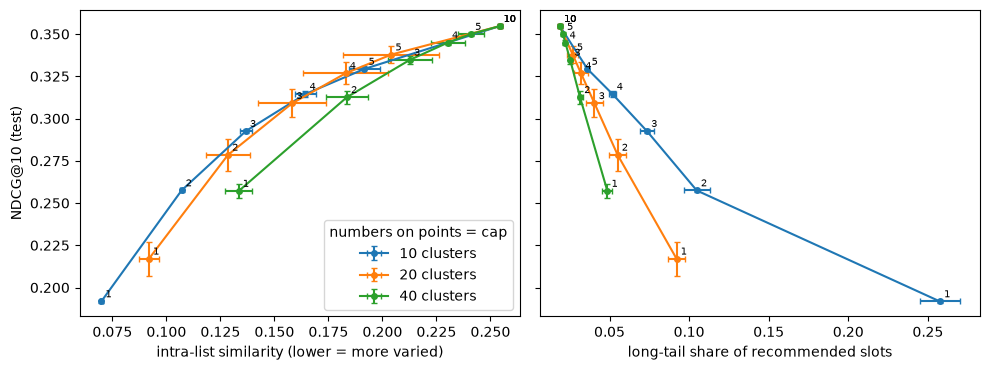

ndcg@10  intra-list similarity  long tail share  coverage  \
clusters cap                                                              
10       1      0.192                  0.070            0.258     0.523   
         2      0.257                  0.107            0.105     0.485   
         3      0.293                  0.137            0.074     0.480   
         4      0.314                  0.164            0.052     0.475   
         5      0.329                  0.192            0.036     0.471   
         10     0.355                  0.254            0.019     0.452   
20       1      0.217                  0.092            0.092     0.481   
         2      0.279                  0.129            0.055     0.481   
         3      0.309                  0.158            0.041     0.475   
         4      0.327                  0.183            0.032     0.468   
         5      0.338                  0.204            0.027     0.462   
         10     0.355                  0.254            0.019     0.452   
40       1      0.257                  0.133            0.049     0.472   
         2      0.313                  0.184            0.031     0.465   
         3      0.335                  0.213            0.025     0.461   
         4      0.345                  0.230            0.022     0.457   
         5      0.350                  0.241            0.021     0.455   
         10     0.355                  0.254            0.019     0.452   

              largest cluster share  
clusters cap                         
10       1                    0.100  
         2                    0.200  
         3                    0.299  
         4                    0.398  
         5                    0.493  
         10                   0.839  
20       1                    0.100  
         2                    0.199  
         3                    0.296  
         4                    0.388  
         5                    0.473  
         10                   0.739  
40       1                    0.099  
         2                    0.194  
         3                    0.277  
         4                    0.346  
         5                    0.398  
         10                   0.493

In [18]:
curve = diversity.groupby(["clusters", "cap"]).agg(["mean", "std"])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for k, part in curve.groupby(level="clusters"):
    for ax, x in zip(axes, ["intra-list similarity", "long tail share"]):
        ax.errorbar(part[(x, "mean")], part[("ndcg@10", "mean")], xerr=part[(x, "std")], yerr=part[("ndcg@10", "std")],
                    marker="o", ms=4, capsize=2, label=f"{k} clusters")
        for cap_value, row in part.iterrows():
            ax.annotate(str(cap_value[1]), (row[(x, "mean")], row[("ndcg@10", "mean")]), fontsize=7,
                        xytext=(3, 3), textcoords="offset points")
axes[0].set_xlabel("intra-list similarity (lower = more varied)")
axes[1].set_xlabel("long-tail share of recommended slots")
axes[0].set_ylabel("NDCG@10 (test)")
axes[0].legend(title="numbers on points = cap")
fig.tight_layout()
fig.savefig(FIGURES / "diversity_tradeoff.pdf")
plt.show()

display(curve.xs("mean", axis=1, level=1)[["ndcg@10", "intra-list similarity", "long tail share", "coverage", "largest cluster share"]].round(3))

**Control: do the clusters matter, or would any cap do?** Any cap pushes the lists deeper into the ranking, which by itself lowers similarity and accuracy. On split 0 we repeat the capping with the cluster labels randomly shuffled between games (cluster sizes kept), three shuffles per cap, at the number of clusters from the curve that agrees best across random starts. If the clusters carry information, real clusters should give lower intra-list similarity than shuffled ones at the same cap.

In [19]:
control_k = int(sweep[sweep["k"].isin(CLUSTER_KS)].sort_values("seed agreement (ARI)")["k"].iloc[-1])
print(f"control at k = {control_k}")
popularity0 = evaluate.popularity_counts(train_full)
sim0 = baselines.item_similarity(baselines.pair_counts(train_full))
real_labels, _, _ = clusters.spherical_kmeans(final.item_factors, control_k, 0)  # as in the split-0 test run
rng = np.random.default_rng(0)
rows = []
for cap in [c for c in CAPS if c < ex.K]:
    for name, labels_used in [("real clusters", real_labels)] + [("shuffled", rng.permutation(real_labels)) for _ in range(3)]:
        recs = diversify.capped_top_k(evaluate.als_scorer(final), train_full, labels_used, cap, ex.K)
        metrics, _ = ex.list_metrics(recs, test, popularity0, sim0)
        rows.append({"cap": cap, "labels": name, **metrics})
control = pd.DataFrame(rows).groupby(["cap", "labels"])[["ndcg@10", "intra-list similarity", "long tail share"]].mean()
display(control.unstack("labels").round(3))

control at k = 10


ndcg@10          intra-list similarity          long tail share  \
labels real clusters shuffled         real clusters shuffled   real clusters   
cap                                                                            
1              0.192    0.326                 0.069    0.230           0.261   
2              0.257    0.353                 0.106    0.252           0.107   
3              0.293    0.356                 0.137    0.253           0.074   
4              0.316    0.356                 0.165    0.254           0.052   
5              0.331    0.356                 0.194    0.254           0.036   

                 
labels shuffled  
cap              
1         0.022  
2         0.019  
3         0.019  
4         0.019  
5         0.019

## Summary of the results

Every number below is printed in a section above. Test numbers are for split 0 unless they say "over splits". ALS uses playtime as confidence; the course methods use only which games were played.

**Data and tuning**
- 59,716 users × 3,718 games and 3.15M played pairs (1.42% of the matrix); every game has at least 20 training players (Section 1).
- Every best setting lies inside the range tried, apart from the stated edges: pairs-only rules and the 512-factor compute cap. The edge extensions added 16 ALS settings, among them α = 30, which is worse than α = 10 for both variants (the α × λ table).
- Regularisation matters more than size. At 128 factors, raising λ from 1 to 300 lifts validation NDCG from 0.144 to 0.245; going from 256 to 512 factors adds 0.002 (α = 3, the λ figure and table).
- α = 3 and α = 10 are within one standard error of each other (SE 0.0009), with and without idf.
- idf weighting is more than one standard error better on validation (0.2576 against 0.2555 for the chosen settings), so ALS + idf is the headline model.
- Convergence: the loss is within 1% of its final value from sweep 6, and three random starts are within 0.0002 NDCG at sweep 15. NDCG still creeps up to 0.2578 at sweep 30, a gain of 0.0001–0.0004 per start, well under one standard error, so 15 sweeps is enough (Section 3).

**Test results**
- NDCG@10: ALS + idf 0.356, ALS 0.350, rules 0.321–0.322, item-kNN 0.302, popularity 0.223. The order is the same on all five splits, and the standard deviation over splits is at most 0.0013 (Section 4).
- ALS + idf beats the best course method on validation (rules, pairs) by +0.035 NDCG, interval [0.033, 0.037] (Bonferroni, four comparisons).
- idf weighting also wins on test (+0.006, [0.005, 0.007]) and recommends more of the catalogue: coverage 0.384 → 0.448, long-tail share 0.012 → 0.019.
- Triples add +0.0007 to the rules, [−0.0000, 0.0014]: tiny, and the corrected interval just touches zero.
- Variety differs a lot between methods. Item-kNN recommends 51% of the games, ALS + idf 45%, ALS 38%, rules 6–7% and popularity 1%. 20.7% of the hidden test games are long-tail games, but no method gives them more than 3.7% of its slots (item-kNN); ALS + idf gives them 1.9%.
- Validation and test NDCG cannot be compared with each other: the test refit trains on 25% more games per user, and each user's test set is larger. Compare methods within one set only.

**Implementation check:** our ALS and `implicit` give scores within 2.0e-8 of each other and identical top-10 lists for all 59,716 users (Section 5).

**Clusters and diversification**
- A vector's length follows the game's number of players (Spearman 0.93), so we cluster directions (Section 6).
- The Davies–Bouldin index falls from 4.06 at k = 5 to 3.12 at k = 80 and does not pick a k. Only k = 5 gives (almost) the same clusters from different random starts (ARI 0.96); at k = 10 the agreement is 0.86, and 0.58 or less above that.
- At k = 5 the AMI with each game's top content tag is 0.16 (0.00 when shuffled). The clusters are shooters, MMO/survival/open world, strategy, puzzle/platformer, and casual/puzzle; the last two share tags. The shooter and MMO clusters hold the most-played games (median 662 and 254 players against 76–129) and 94% of all ALS top-10 slots, so the clusters partly follow popularity.
- At k = 10, 84% of all ALS top-10 slots fall in a single cluster.
- Capping games per cluster trades accuracy for variety (Section 7, means over splits). With 10 clusters and a cap of 3, NDCG goes from 0.355 to 0.293, intra-list similarity from 0.254 to 0.137 and the long-tail share from 0.019 to 0.074. A cap of 1 brings NDCG to 0.192 and the long-tail share to 0.258.
- The control shows that the gain in variety comes from the clusters, not from capping as such (split 0, 10 clusters). With shuffled labels a cap of 1 costs some accuracy (NDCG 0.326 against 0.356 uncapped) but hardly changes variety (similarity 0.230 against 0.254, long-tail share 0.022 against 0.019); with the real clusters it gives NDCG 0.192, similarity 0.069 and long-tail share 0.261.